In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

uploaded = files.upload()
file_name = next(iter(uploaded))

print("Uploaded:", file_name)


Saving Book2.xlsx to Book2.xlsx
Uploaded: Book2.xlsx


In [ ]:
customer = pd.read_excel(file_name, sheet_name="Customer")
product = pd.read_excel(file_name, sheet_name="Product")
product_subcategory = pd.read_excel(file_name, sheet_name="Product Subcategory")
product_category = pd.read_excel(file_name, sheet_name="Product Category")
discounts = pd.read_excel(file_name, sheet_name="Discounts")
returns = pd.read_excel(file_name, sheet_name="Returns")
calendar = pd.read_excel(file_name, sheet_name="Calendar")
territory = pd.read_excel(file_name, sheet_name="Territory ")

sales_2020 = pd.read_excel(file_name, sheet_name="Sales Data 2020")
sales_2021 = pd.read_excel(file_name, sheet_name="Sales Data 2021")
sales_2022 = pd.read_excel(file_name, sheet_name="Sales Data 2022")

sales_2021 = sales_2021.rename(columns={"C": "OrderDate"})

for df in [sales_2020, sales_2021, sales_2022]:
    df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")
    df["StockDate"] = pd.to_datetime(df["StockDate"], errors="coerce")

returns["ReturnDate"] = pd.to_datetime(returns["ReturnDate"], errors="coerce")

print("Tables loaded successfully.")


Tables loaded successfully.


In [ ]:
sales = pd.concat(
    [sales_2020, sales_2021, sales_2022],
    ignore_index=True
)

print("Combined sales shape:", sales.shape)
sales.head()

Combined sales shape: (56046, 8)


,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity
0,2020-01-01,2019-09-21,SO45080,332,14657,1,1,1
1,2020-01-01,2019-12-05,SO45079,312,29255,4,1,1
2,2020-01-01,2019-10-29,SO45082,350,11455,9,1,1
3,2020-01-01,2019-11-16,SO45081,338,26782,6,1,1
4,2020-01-02,2019-12-15,SO45083,312,14947,10,1,1


In [ ]:
sales["OrderDate"].dt.year.value_counts().sort_index()


,count
OrderDate,
2020,2630
2021,23935
2022,29481


In [ ]:
print("Total sales rows:", sales.shape[0])
print("Earliest order date:", sales["OrderDate"].min())
print("Latest order date:", sales["OrderDate"].max())
print("Rows from each year:")
print(sales["OrderDate"].dt.year.value_counts().sort_index())


Total sales rows: 56046
Earliest order date: 2020-01-01 00:00:00
Latest order date: 2022-06-30 00:00:00
Rows from each year:
OrderDate
2020     2630
2021    23935
2022    29481
Name: count, dtype: int64


In [ ]:
sales_product = sales.merge(
    product,
    on="ProductKey",
    how="left",
    validate="many_to_one"
)

print("Sales + Product shape:", sales_product.shape)
sales_product.head()


Sales + Product shape: (56046, 18)


,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductSize,ProductStyle,ProductCost,ProductPrice
0,2020-01-01,2019-09-21,SO45080,332,14657,1,1,1,2,BK-R50B-58,"Road-650 Black, 58",Road-650,Value-priced bike with many features of our to...,Black,58,U,413.1463,699.0982
1,2020-01-01,2019-12-05,SO45079,312,29255,4,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700
2,2020-01-01,2019-10-29,SO45082,350,11455,9,1,1,1,BK-M82B-44,"Mountain-100 Black, 44",Mountain-100,Top-of-the-line competition mountain bike. Per...,Black,44,U,1898.0944,3374.9900
3,2020-01-01,2019-11-16,SO45081,338,26782,6,1,1,2,BK-R50B-44,"Road-650 Black, 44",Road-650,Value-priced bike with many features of our to...,Black,44,U,413.1463,699.0982
4,2020-01-02,2019-12-15,SO45083,312,14947,10,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700


In [ ]:
print("Missing ProductName after merge:",
      sales_product["ProductName"].isna().sum())


Missing ProductName after merge: 0


In [ ]:
sales_product = sales_product.merge(
    product_subcategory[[
        "ProductSubcategoryKey",
        "SubcategoryName",
        "ProductCategoryKey"
    ]],
    on="ProductSubcategoryKey",
    how="left",
    validate="many_to_one"
)

sales_product = sales_product.merge(
    product_category,
    on="ProductCategoryKey",
    how="left",
    validate="many_to_one"
)

sales_product.head()


,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductSize,ProductStyle,ProductCost,ProductPrice,SubcategoryName,ProductCategoryKey,CategoryName
0,2020-01-01,2019-09-21,SO45080,332,14657,1,1,1,2,BK-R50B-58,"Road-650 Black, 58",Road-650,Value-priced bike with many features of our to...,Black,58,U,413.1463,699.0982,Road Bikes,1,Bikes
1,2020-01-01,2019-12-05,SO45079,312,29255,4,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes
2,2020-01-01,2019-10-29,SO45082,350,11455,9,1,1,1,BK-M82B-44,"Mountain-100 Black, 44",Mountain-100,Top-of-the-line competition mountain bike. Per...,Black,44,U,1898.0944,3374.9900,Mountain Bikes,1,Bikes
3,2020-01-01,2019-11-16,SO45081,338,26782,6,1,1,2,BK-R50B-44,"Road-650 Black, 44",Road-650,Value-priced bike with many features of our to...,Black,44,U,413.1463,699.0982,Road Bikes,1,Bikes
4,2020-01-02,2019-12-15,SO45083,312,14947,10,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes


In [ ]:
sales_full = sales_product.merge(
    customer,
    on="CustomerKey",
    how="left",
    validate="many_to_one"
)

print("Analysis dataset shape:", sales_full.shape)
sales_full.head()


Analysis dataset shape: (56046, 33)


,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductSize,ProductStyle,ProductCost,ProductPrice,SubcategoryName,ProductCategoryKey,CategoryName,Prefix,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,TotalChildren,EducationLevel,Occupation,HomeOwner
0,2020-01-01,2019-09-21,SO45080,332,14657,1,1,1,2,BK-R50B-58,"Road-650 Black, 58",Road-650,Value-priced bike with many features of our to...,Black,58,U,413.1463,699.0982,Road Bikes,1,Bikes,MR.,JOHN,THOMAS,1958-11-11,M,M,john48@adventure-works.com,80000,1,Partial College,Skilled Manual,N
1,2020-01-01,2019-12-05,SO45079,312,29255,4,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes,MR.,KYLE,WASHINGTON,1955-04-11,S,M,kyle8@adventure-works.com,80000,3,Partial College,Professional,N
2,2020-01-01,2019-10-29,SO45082,350,11455,9,1,1,1,BK-M82B-44,"Mountain-100 Black, 44",Mountain-100,Top-of-the-line competition mountain bike. Per...,Black,44,U,1898.0944,3374.9900,Mountain Bikes,1,Bikes,MR.,ROSS,SANZ,1974-04-21,M,M,ross38@adventure-works.com,100000,0,High School,Management,Y
3,2020-01-01,2019-11-16,SO45081,338,26782,6,1,1,2,BK-R50B-44,"Road-650 Black, 44",Road-650,Value-priced bike with many features of our to...,Black,44,U,413.1463,699.0982,Road Bikes,1,Bikes,MR.,SETH,LEWIS,1980-09-25,S,M,seth20@adventure-works.com,30000,0,High School,Skilled Manual,N
4,2020-01-02,2019-12-15,SO45083,312,14947,10,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes,MR.,ALEJANDRO,CHEN,1965-01-11,S,M,alejandro4@adventure-works.com,20000,2,High School,Manual,Y


In [ ]:
# Rename columns in territory because they were imported without a proper header name for the key
territory.columns = ["SalesTerritoryKey", "Region", "Country", "Continent"]

sales_full = sales_full.merge(
    territory,
    left_on="TerritoryKey",
    right_on="SalesTerritoryKey",
    how="left",
    validate="many_to_one"
)

sales_full.head()

,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductSize,ProductStyle,ProductCost,ProductPrice,SubcategoryName,ProductCategoryKey,CategoryName,Prefix,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,TotalChildren,EducationLevel,Occupation,HomeOwner,SalesTerritoryKey,Region,Country,Continent
0,2020-01-01,2019-09-21,SO45080,332,14657,1,1,1,2,BK-R50B-58,"Road-650 Black, 58",Road-650,Value-priced bike with many features of our to...,Black,58,U,413.1463,699.0982,Road Bikes,1,Bikes,MR.,JOHN,THOMAS,1958-11-11,M,M,john48@adventure-works.com,80000,1,Partial College,Skilled Manual,N,1,Northwest,United States,North America
1,2020-01-01,2019-12-05,SO45079,312,29255,4,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes,MR.,KYLE,WASHINGTON,1955-04-11,S,M,kyle8@adventure-works.com,80000,3,Partial College,Professional,N,4,Southwest,United States,North America
2,2020-01-01,2019-10-29,SO45082,350,11455,9,1,1,1,BK-M82B-44,"Mountain-100 Black, 44",Mountain-100,Top-of-the-line competition mountain bike. Per...,Black,44,U,1898.0944,3374.9900,Mountain Bikes,1,Bikes,MR.,ROSS,SANZ,1974-04-21,M,M,ross38@adventure-works.com,100000,0,High School,Management,Y,9,Australia,Australia,Pacific
3,2020-01-01,2019-11-16,SO45081,338,26782,6,1,1,2,BK-R50B-44,"Road-650 Black, 44",Road-650,Value-priced bike with many features of our to...,Black,44,U,413.1463,699.0982,Road Bikes,1,Bikes,MR.,SETH,LEWIS,1980-09-25,S,M,seth20@adventure-works.com,30000,0,High School,Skilled Manual,N,6,Canada,Canada,North America
4,2020-01-02,2019-12-15,SO45083,312,14947,10,1,1,2,BK-R93R-48,"Road-150 Red, 48",Road-150,This bike is ridden by race winners. Developed...,Red,48,U,2171.2942,3578.2700,Road Bikes,1,Bikes,MR.,ALEJANDRO,CHEN,1965-01-11,S,M,alejandro4@adventure-works.com,20000,2,High School,Manual,Y,10,United Kingdom,United Kingdom,Europe


In [ ]:
sales_full["Revenue"] = (
    sales_full["ProductPrice"] * sales_full["OrderQuantity"]
)

sales_full["Cost"] = (
    sales_full["ProductCost"] * sales_full["OrderQuantity"]
)

sales_full["Margin"] = (
    sales_full["Revenue"] - sales_full["Cost"]
)

sales_full["MarginPct"] = np.where(
    sales_full["Revenue"] != 0,
    sales_full["Margin"] / sales_full["Revenue"] * 100,
    np.nan
)

sales_full[[
    "ProductName",
    "OrderQuantity",
    "ProductPrice",
    "Revenue",
    "Cost",
    "Margin",
    "MarginPct"
]].head()


,ProductName,OrderQuantity,ProductPrice,Revenue,Cost,Margin,MarginPct
0,"Road-650 Black, 58",1,699.0982,699.0982,413.1463,285.9519,40.902966
1,"Road-150 Red, 48",1,3578.2700,3578.2700,2171.2942,1406.9758,39.320001
2,"Mountain-100 Black, 44",1,3374.9900,3374.9900,1898.0944,1476.8956,43.759999
3,"Road-650 Black, 44",1,699.0982,699.0982,413.1463,285.9519,40.902966
4,"Road-150 Red, 48",1,3578.2700,3578.2700,2171.2942,1406.9758,39.320001


In [ ]:
# Clean up duplicated CategoryName column from previous merges
if "CategoryName_y" in sales_full.columns:
    sales_full = sales_full.rename(columns={"CategoryName_y": "CategoryName"})

category_summary = (
    sales_full
    .groupby("CategoryName", as_index=False)
    .agg(
        TotalQuantity=("OrderQuantity", "sum"),
        Revenue=("Revenue", "sum"),
        Margin=("Margin", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

category_summary

,CategoryName,TotalQuantity,Revenue,Margin
1,Bikes,13929,2.364250e+07,9.726168e+06
0,Accessories,57809,9.066731e+05,5.697601e+05
2,Clothing,12436,3.654186e+05,1.617871e+05


In [ ]:
product_summary = (
    sales_full
    .groupby(["ProductKey", "ProductName"], as_index=False)
    .agg(
        UnitsSold=("OrderQuantity", "sum"),
        Revenue=("Revenue", "sum"),
        AveragePrice=("ProductPrice", "mean"),
        Margin=("Margin", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

product_summary.head(10)


,ProductKey,ProductName,UnitsSold,Revenue,AveragePrice,Margin
38,362,"Mountain-200 Black, 46",606,1.241754e+06,2049.0982,571632.6492
37,360,"Mountain-200 Black, 42",602,1.233557e+06,2049.0982,567859.4964
33,352,"Mountain-200 Silver, 38",586,1.213852e+06,2071.4196,558788.3282
35,356,"Mountain-200 Silver, 46",571,1.182781e+06,2071.4196,544484.8727
36,358,"Mountain-200 Black, 38",569,1.165937e+06,2049.0982,536730.9858
34,354,"Mountain-200 Silver, 42",547,1.133067e+06,2071.4196,521599.3439
45,377,"Road-250 Black, 52",316,6.893738e+05,2181.5625,272037.6692
42,371,"Road-250 Red, 58",303,6.610134e+05,2181.5625,260846.2461
44,375,"Road-250 Black, 48",294,6.413794e+05,2181.5625,253098.3378
10,312,"Road-150 Red, 48",179,6.405103e+05,3578.2700,251848.6682


In [ ]:
customer_summary = (
    sales_full
    .groupby(
        [
            "CustomerKey", "FirstName", "LastName",
            "Gender", "AnnualIncome", "Occupation",
            "EducationLevel", "HomeOwner"
        ],
        as_index=False
    )
    .agg(
        Orders=("OrderNumber", "nunique"),
        UnitsPurchased=("OrderQuantity", "sum"),
        Revenue=("Revenue", "sum"),
        Margin=("Margin", "sum")
    )
)

customer_summary.head()


,CustomerKey,FirstName,LastName,Gender,AnnualIncome,Occupation,EducationLevel,HomeOwner,Orders,UnitsPurchased,Revenue,Margin
0,11000,JON,YANG,M,90000,Professional,Bachelors,Y,2,10,4656.3896,1960.0790
1,11001,EUGENE,HUANG,M,60000,Professional,Bachelors,N,2,15,2821.2122,1255.4709
2,11002,RUBEN,TORRES,M,60000,Professional,Bachelors,Y,2,3,4466.8124,1867.0367
3,11003,CHRISTY,ZHU,F,70000,Professional,Bachelors,N,2,11,4532.9866,1902.9618
4,11004,ELIZABETH,JOHNSON,F,80000,Professional,Bachelors,Y,2,6,4568.0838,1926.7349


In [ ]:
# Clean up overlapping territory columns from previous merges
sales_full = sales_full.rename(columns={
    "Continent_y": "Continent",
    "Country_y": "Country",
    "Region_y": "Region"
})

territory_summary = (
    sales_full
    .groupby(["Continent", "Country", "Region"], as_index=False)
    .agg(
        Orders=("OrderNumber", "nunique"),
        UnitsSold=("OrderQuantity", "sum"),
        Revenue=("Revenue", "sum"),
        Margin=("Margin", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

territory_summary.head(10)

,Continent,Country,Region,Orders,UnitsSold,Revenue,Margin
9,Pacific,Australia,Australia,6060,17951,7.416456e+06,3.077023e+06
8,North America,United States,Southwest,4992,17191,4.822795e+06,2.040345e+06
6,North America,United States,Northwest,3675,12513,3.095074e+06,1.314751e+06
2,Europe,United Kingdom,United Kingdom,2771,9694,2.902562e+06,1.214774e+06
1,Europe,Germany,Germany,2294,7950,2.524680e+06,1.054186e+06
0,Europe,France,France,2315,7862,2.362643e+06,9.893461e+05
3,North America,Canada,Canada,3024,10894,1.769246e+06,7.578442e+05
7,North America,United States,Southeast,14,49,1.158562e+04,5.133288e+03
5,North America,United States,Northeast,10,40,6.401568e+03,2.874582e+03
4,North America,United States,Central,9,30,3.143060e+03,1.437441e+03


In [ ]:
sales_full["Year"] = sales_full["OrderDate"].dt.year
sales_full["Quarter"] = sales_full["OrderDate"].dt.quarter
sales_full["Month"] = sales_full["OrderDate"].dt.month
sales_full["MonthName"] = sales_full["OrderDate"].dt.month_name()
sales_full["DayOfWeek"] = sales_full["OrderDate"].dt.day_name()

sales_full[[
    "OrderDate", "Year", "Quarter",
    "Month", "MonthName", "DayOfWeek"
]].head()


,OrderDate,Year,Quarter,Month,MonthName,DayOfWeek
0,2020-01-01,2020,1,1,January,Wednesday
1,2020-01-01,2020,1,1,January,Wednesday
2,2020-01-01,2020,1,1,January,Wednesday
3,2020-01-01,2020,1,1,January,Wednesday
4,2020-01-02,2020,1,1,January,Thursday


## Monthly revenue


In [ ]:
monthly_sales = (
    sales_full
    .groupby(pd.Grouper(key="OrderDate", freq="MS"))
    .agg(
        Revenue=("Revenue", "sum"),
        UnitsSold=("OrderQuantity", "sum"),
        Orders=("OrderNumber", "nunique")
    )
    .reset_index()
)

monthly_sales.head(12)


,OrderDate,Revenue,UnitsSold,Orders
0,2020-01-01,585312.6486,184,184
1,2020-02-01,532226.2458,165,165
2,2020-03-01,643436.1040,198,198
3,2020-04-01,653364.0368,204,204
4,2020-05-01,659325.8968,206,206
5,2020-06-01,669988.6696,212,212
6,2020-07-01,486115.0054,247,247
7,2020-08-01,536452.8175,278,278
8,2020-09-01,344062.8749,196,196
9,2020-10-01,404276.5974,223,223


In [ ]:
yearly_sales = (
    sales_full
    .groupby("Year", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        UnitsSold=("OrderQuantity", "sum"),
        Orders=("OrderNumber", "nunique"),
        Margin=("Margin", "sum")
    )
)

yearly_sales


,Year,Revenue,UnitsSold,Orders,Margin
0,2020,6.404934e+06,2630,2630,2.601602e+06
1,2021,9.324204e+06,36230,10695,3.967084e+06
2,2022,9.185449e+06,45314,11839,3.889029e+06


In [ ]:
highest_revenue_category = sales_full.groupby('CategoryName')['Revenue'].sum().idxmax()
print(highest_revenue_category)

Bikes


In [ ]:
highest_revenue_category = sales_full.groupby('CategoryName')['Revenue'].sum().idxmax()
print(highest_revenue_category)

Bikes


In [ ]:
top10_products = sales_full.groupby('ProductName')['Revenue'].sum().nlargest(10)
print(top10_products)

ProductName
Mountain-200 Black, 46     1.241754e+06
Mountain-200 Black, 42     1.233557e+06
Mountain-200 Silver, 38    1.213852e+06
Mountain-200 Silver, 46    1.182781e+06
Mountain-200 Black, 38     1.165937e+06
Mountain-200 Silver, 42    1.133067e+06
Road-250 Black, 52         6.893738e+05
Road-250 Red, 58           6.610134e+05
Road-250 Black, 48         6.413794e+05
Road-150 Red, 48           6.405103e+05
Name: Revenue, dtype: float64


In [ ]:
territory_with_highest_revenue = sales_full.groupby('Region')['Revenue'].sum().idxmax()
print(territory_with_highest_revenue)

Australia


In [ ]:
year_highest_revenue = sales_full.groupby('Year')['Revenue'].sum().idxmax()
print(year_highest_revenue)

2021


In [ ]:
month_highest_revenue = sales_full.groupby('MonthName')['Revenue'].sum().idxmax()
print(month_highest_revenue)

June


In [ ]:
customer_highest_revenue = sales_full.groupby(['FirstName', 'LastName'])['Revenue'].sum().idxmax()
print(customer_highest_revenue)

('JORDAN', 'TURNER')


In [ ]:
average_order_quantity = sales_full['OrderQuantity'].mean()
print(average_order_quantity)

1.5018734610855369


In [ ]:
Occupation_highest_revenue = sales_full.groupby('Occupation')['Revenue'].sum().idxmax()
print(Occupation_highest_revenue)

Professional


In [ ]:
highest_margin_category = sales_full.groupby('CategoryName')['MarginPct'].mean().idxmax()
print(highest_margin_category)

Accessories


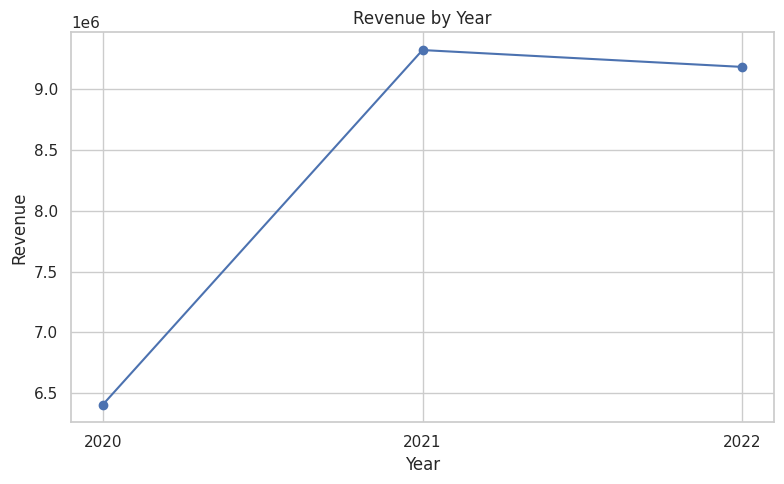

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_sales["Year"],
    yearly_sales["Revenue"],
    marker="o"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(yearly_sales["Year"])
plt.tight_layout()
plt.show()


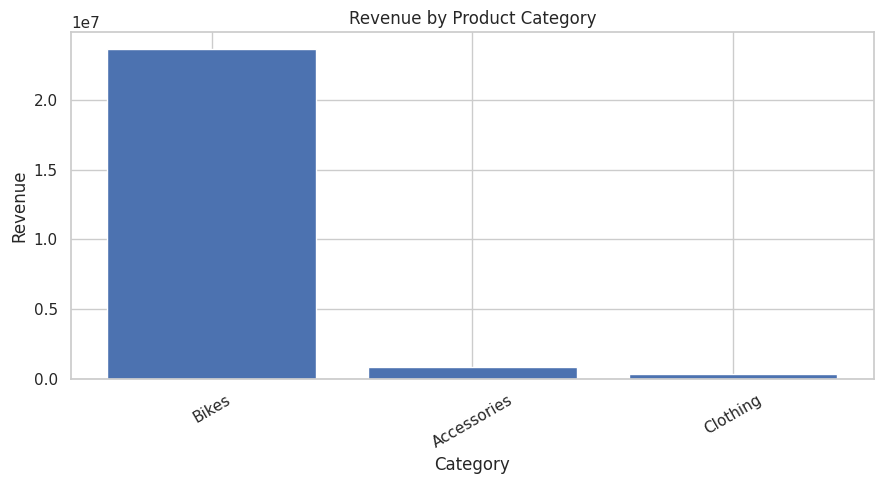

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_summary["CategoryName"],
    category_summary["Revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


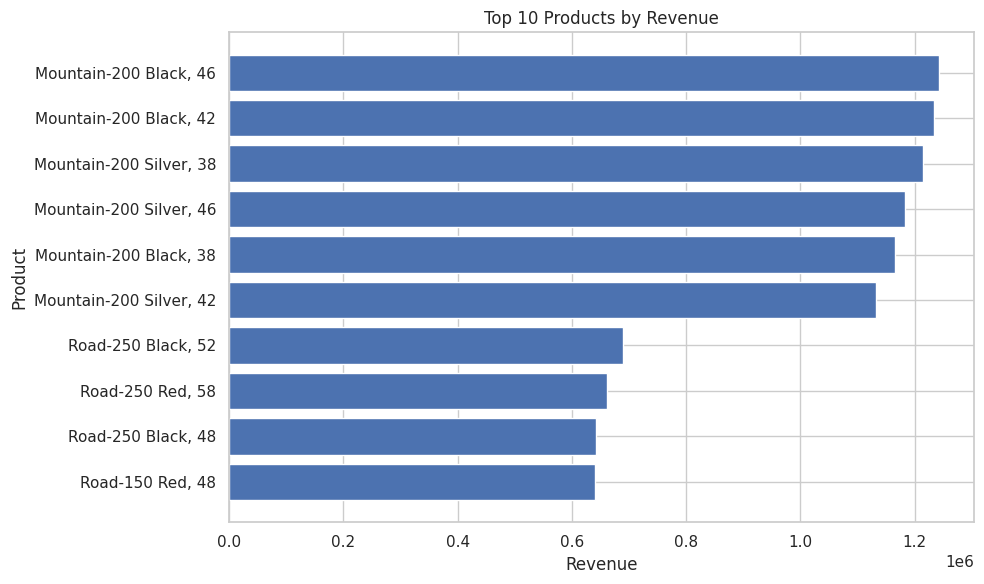

In [ ]:
top10_products = product_summary.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top10_products["ProductName"],
    top10_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


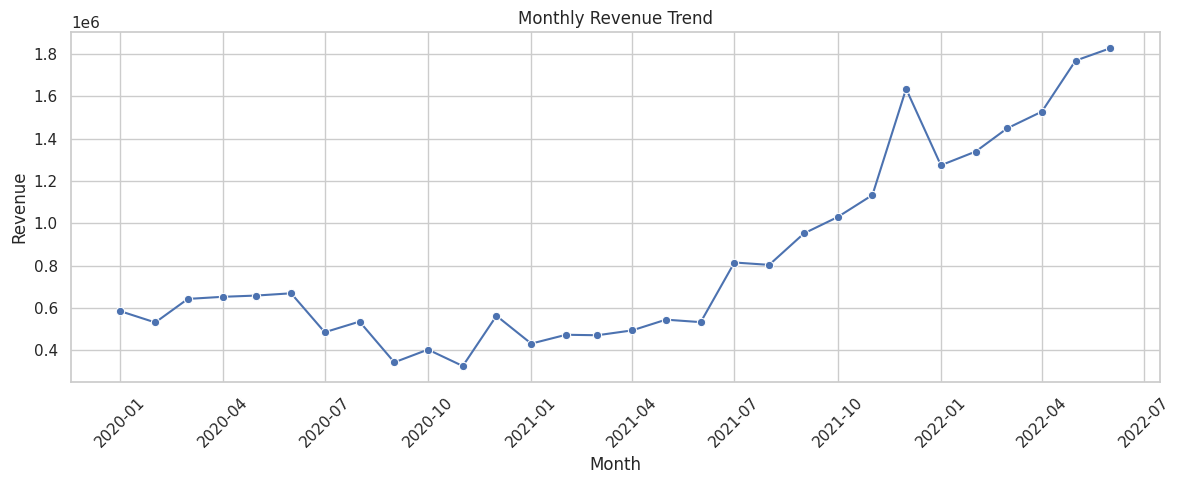

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="OrderDate",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


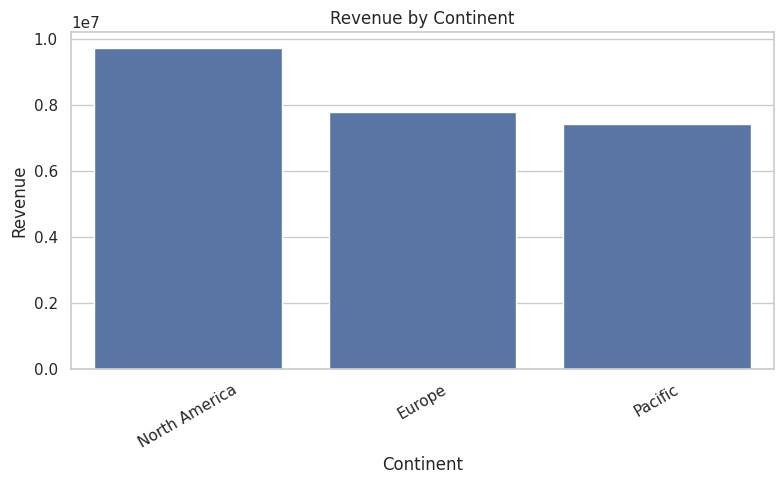

In [ ]:
continent_summary = (
    sales_full
    .groupby("Continent", as_index=False)
    .agg(Revenue=("Revenue", "sum"))
    .sort_values("Revenue", ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=continent_summary,
    x="Continent",
    y="Revenue"
)

plt.title("Revenue by Continent")
plt.xlabel("Continent")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


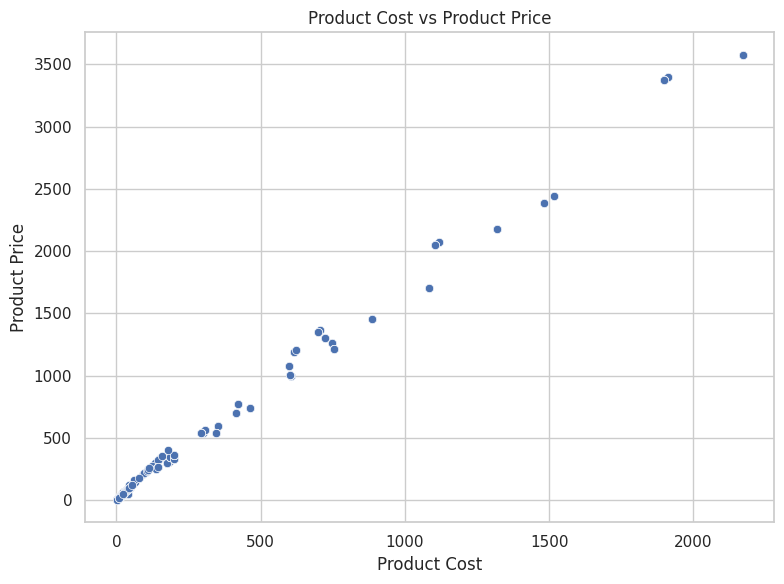

In [ ]:
product_unique = product.drop_duplicates("ProductKey").copy()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=product_unique,
    x="ProductCost",
    y="ProductPrice"
)

plt.title("Product Cost vs Product Price")
plt.xlabel("Product Cost")
plt.ylabel("Product Price")
plt.tight_layout()
plt.show()


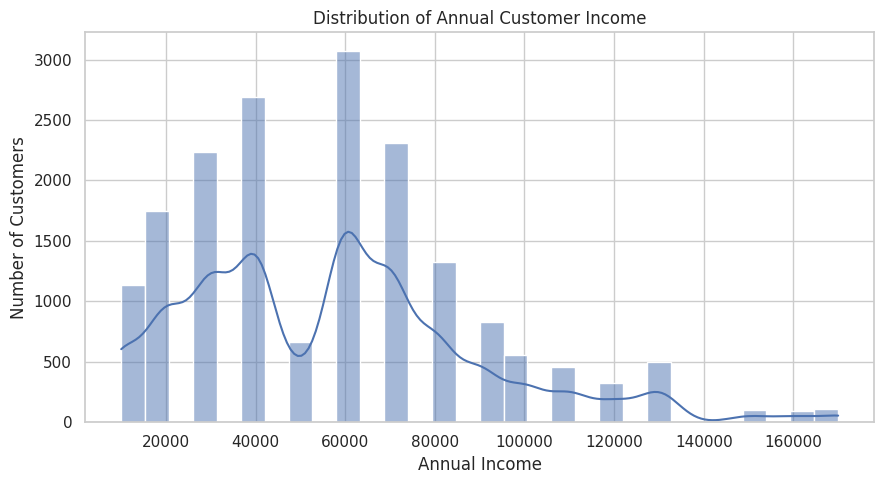

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=customer,
    x="AnnualIncome",
    bins=30,
    kde=True
)

plt.title("Distribution of Annual Customer Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


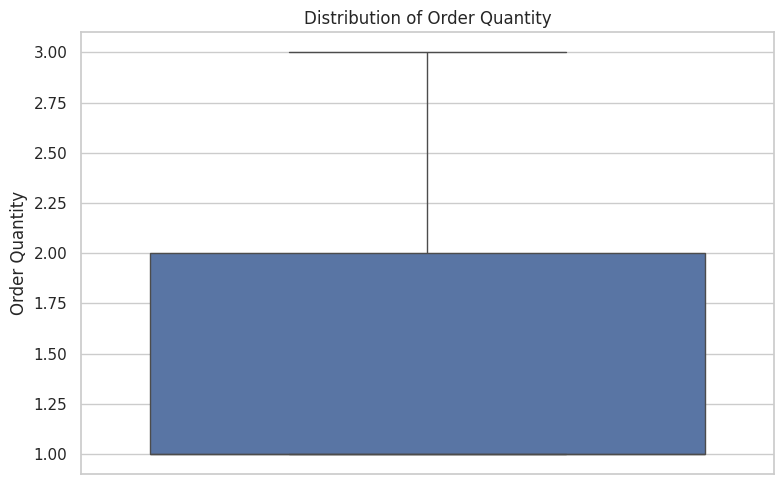

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=sales_full,
    y="OrderQuantity"
)

plt.title("Distribution of Order Quantity")
plt.ylabel("Order Quantity")
plt.tight_layout()
plt.show()


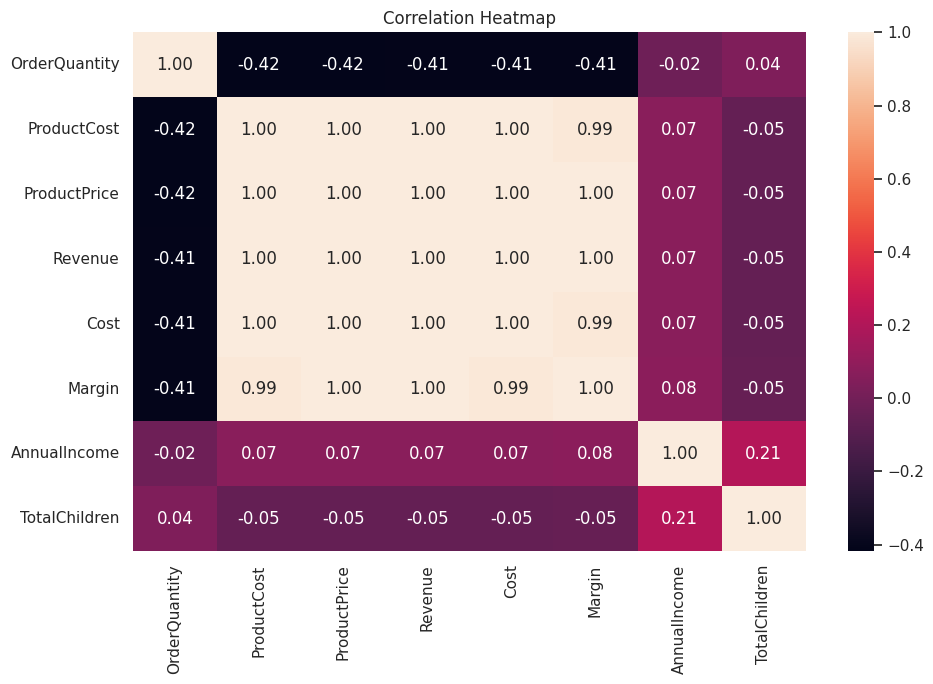

In [ ]:
numeric_cols = [
    "OrderQuantity",
    "ProductCost",
    "ProductPrice",
    "Revenue",
    "Cost",
    "Margin",
    "AnnualIncome",
    "TotalChildren"
]

corr = sales_full[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


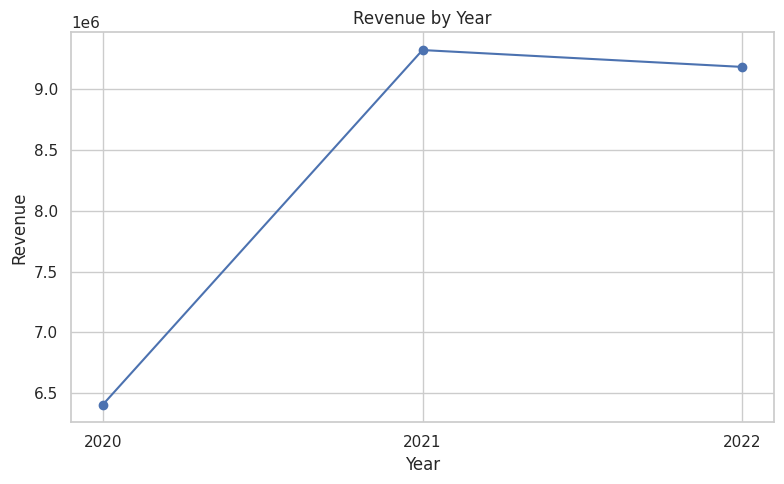

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    yearly_sales["Year"],
    yearly_sales["Revenue"],
    marker="o"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(yearly_sales["Year"])
plt.tight_layout()
plt.show()


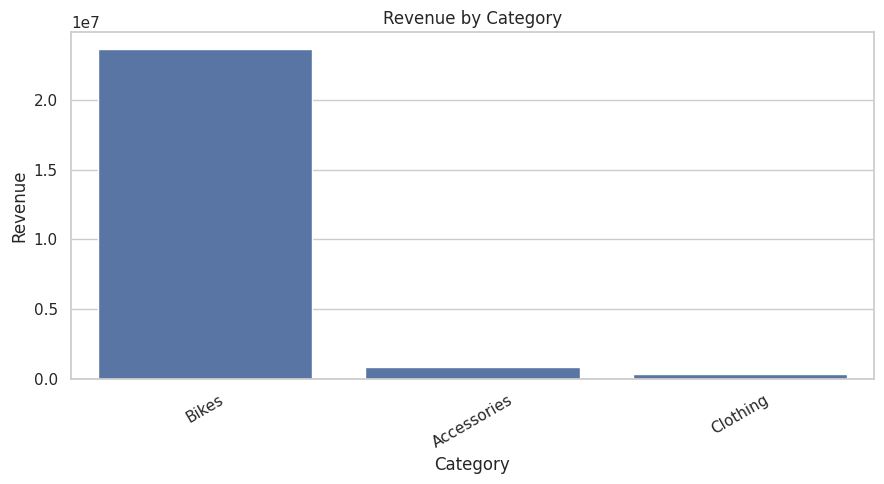

In [ ]:
# YOUR PRACTICE — Visualization 2
plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_summary,
    x="CategoryName",
    y="Revenue"
)

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

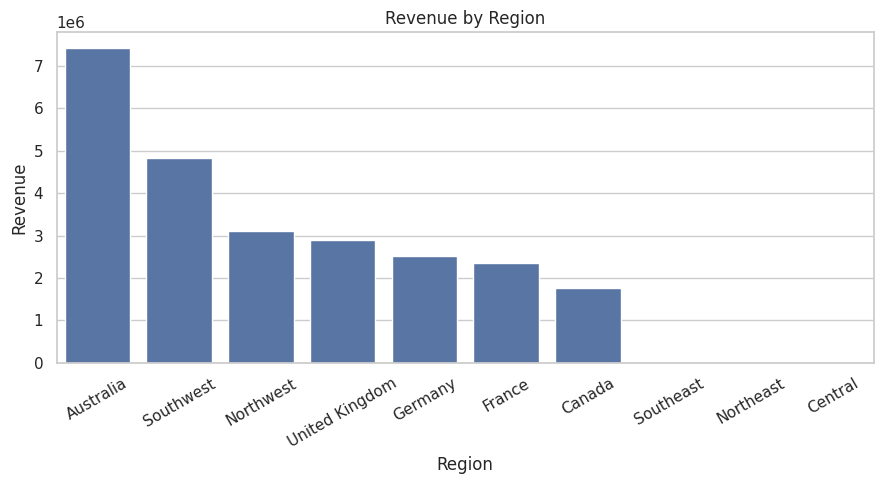

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=territory_summary,
    x="Region",
    y="Revenue"
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
total_revenue = sales_full["Revenue"].sum()
total_cost = sales_full["Cost"].sum()
total_margin = sales_full["Margin"].sum()
total_units = sales_full["OrderQuantity"].sum()
total_orders = sales_full["OrderNumber"].nunique()
total_customers = sales_full["CustomerKey"].nunique()
total_products = sales_full["ProductKey"].nunique()

kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Margin",
        "Units Sold",
        "Orders",
        "Unique Customers",
        "Unique Products"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_margin,
        total_units,
        total_orders,
        total_customers,
        total_products
    ]
})

kpis


,KPI,Value
0,Total Revenue,2.491459e+07
1,Total Cost,1.445687e+07
2,Total Margin,1.045772e+07
3,Units Sold,8.417400e+04
4,Orders,2.516400e+04
5,Unique Customers,1.741600e+04
6,Unique Products,1.300000e+02


In [ ]:
aov = total_revenue / total_orders

print(f"Average Order Value: ${aov:,.2f}")


Average Order Value: $990.09


In [ ]:
overall_margin_pct = (total_margin / total_revenue) * 100

print(f"Overall Margin %: {overall_margin_pct:.2f}%")


Overall Margin %: 41.97%


In [ ]:
category_margin = (
    sales_full
    .groupby("CategoryName", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Cost=("Cost", "sum"),
        Margin=("Margin", "sum")
    )
)

category_margin["MarginPct"] = (
    category_margin["Margin"] / category_margin["Revenue"] * 100
)

category_margin.sort_values("MarginPct", ascending=False)


,CategoryName,Revenue,Cost,Margin,MarginPct
0,Accessories,9.066731e+05,3.369130e+05,5.697601e+05,62.840737
2,Clothing,3.654186e+05,2.036315e+05,1.617871e+05,44.274455
1,Bikes,2.364250e+07,1.391633e+07,9.726168e+06,41.138502


In [ ]:
returned_quantity = returns["ReturnQuantity"].sum()
sold_quantity = sales_full["OrderQuantity"].sum()

overall_return_rate = returned_quantity / sold_quantity * 100

print("Returned quantity:", returned_quantity)
print("Sold quantity:", sold_quantity)
print(f"Overall quantity return rate: {overall_return_rate:.2f}%")


Returned quantity: 1828
Sold quantity: 84174
Overall quantity return rate: 2.17%


In [ ]:
sold_by_product = (
    sales_full
    .groupby("ProductKey", as_index=False)
    .agg(SoldQuantity=("OrderQuantity", "sum"))
)

returned_by_product = (
    returns
    .groupby("ProductKey", as_index=False)
    .agg(ReturnQuantity=("ReturnQuantity", "sum"))
)

product_returns = sold_by_product.merge(
    returned_by_product,
    on="ProductKey",
    how="left"
)

product_returns["ReturnQuantity"] = product_returns["ReturnQuantity"].fillna(0)

product_returns["ReturnRatePct"] = (
    product_returns["ReturnQuantity"] /
    product_returns["SoldQuantity"] * 100
)

product_returns = product_returns.merge(
    product[["ProductKey", "ProductName"]],
    on="ProductKey",
    how="left"
)

product_returns.sort_values(
    "ReturnRatePct",
    ascending=False
).head(10)


,ProductKey,SoldQuantity,ReturnQuantity,ReturnRatePct,ProductName
18,330,51,6.0,11.764706,"Road-650 Red, 52"
27,346,24,2.0,8.333333,"Mountain-100 Silver, 44"
103,577,96,8.0,8.333333,"Touring-2000 Blue, 46"
126,600,41,3.0,7.317073,"Mountain-500 Black, 52"
31,350,31,2.0,6.451613,"Mountain-100 Black, 44"
91,565,54,3.0,5.555556,"Touring-3000 Blue, 54"
32,351,36,2.0,5.555556,"Mountain-100 Black, 48"
17,328,75,4.0,5.333333,"Road-650 Red, 48"
119,593,38,2.0,5.263158,"Mountain-500 Silver, 44"
14,322,39,2.0,5.128205,"Road-650 Red, 60"


In [ ]:
customer_summary["CustomerSegment"] = np.select(
    [
        customer_summary["Revenue"] >= customer_summary["Revenue"].quantile(0.75),
        customer_summary["Revenue"] >= customer_summary["Revenue"].quantile(0.50)
    ],
    [
        "High Value",
        "Medium Value"
    ],
    default="Low Value"
)

customer_summary["CustomerSegment"].value_counts()


,count
CustomerSegment,
Low Value,8517
Medium Value,4451
High Value,4325


In [ ]:
segment_summary = (
    customer_summary
    .groupby("CustomerSegment", as_index=False)
    .agg(
        Customers=("CustomerKey", "count"),
        Revenue=("Revenue", "sum"),
        AverageRevenue=("Revenue", "mean"),
        UnitsPurchased=("UnitsPurchased", "sum")
    )
)

segment_summary


,CustomerSegment,Customers,Revenue,AverageRevenue,UnitsPurchased
0,High Value,4325,1.829845e+07,4230.856206,24536
1,Low Value,8517,7.129054e+05,83.703812,39803
2,Medium Value,4451,5.747314e+06,1291.241134,19246


In [ ]:
customer_summary["IncomeSegment"] = pd.cut(
    customer_summary["AnnualIncome"],
    bins=[-np.inf, 50000, 100000, np.inf],
    labels=["Lower Income", "Middle Income", "Higher Income"]
)

customer_summary["IncomeSegment"].value_counts()


,count
IncomeSegment,
Lower Income,8052
Middle Income,7711
Higher Income,1530


In [ ]:
top_customers = customer_summary.sort_values(
    "Revenue",
    ascending=False
).head(10)

top_customers[[
    "CustomerKey",
    "FirstName",
    "LastName",
    "Occupation",
    "AnnualIncome",
    "Orders",
    "Revenue",
    "Margin"
]]


,CustomerKey,FirstName,LastName,Occupation,AnnualIncome,Orders,Revenue,Margin
415,11433,MAURICE,SHAN,Professional,80000,6,12407.9545,5074.7670
420,11439,JANET,MUNOZ,Management,90000,6,12015.4029,4971.5382
229,11241,LISA,CAI,Professional,100000,7,11330.4494,4780.9088
399,11417,LACEY,ZHENG,Professional,70000,7,11085.7504,4650.9561
402,11420,JORDAN,TURNER,Management,100000,7,11022.4002,4611.7390
230,11242,LARRY,MUNOZ,Professional,110000,7,10852.0340,4505.9653
2169,13263,KATE,ANAND,Professional,110000,4,10436.5079,4246.1004
1589,12655,LARRY,VAZQUEZ,Management,80000,4,10394.9836,4222.8261
407,11425,ARIANA,GRAY,Professional,90000,6,10391.4304,4403.1453
1565,12631,CLARENCE,GAO,Professional,70000,4,10331.7349,4200.6771


In [ ]:
total_revenue = sales_full["Revenue"].sum()
total_margin = sales_full["Margin"].sum()
overall_margin_pct = (total_margin / total_revenue) * 100
aov = (total_revenue / total_orders)

print("Total Revenue:", total_revenue)
print("Total Margin:", total_margin)
print("Overall Margin %:", overall_margin_pct)
print("Average Order Value:", aov)


Total Revenue: 24914586.8193
Total Margin: 10457715.4342
Overall Margin %: 41.97426796618183
Average Order Value: 990.0884922627563


In [ ]:
highest_revenue_category = category_summary.loc[
    category_summary["Revenue"].idxmax(),
    "CategoryName"
]

print( highest_revenue_category)

Bikes


In [ ]:
# Calculate MarginPct dynamically first
category_summary["MarginPct"] = (category_summary["Margin"] / category_summary["Revenue"]) * 100

# Retrieve the row with the maximum MarginPct and extract its 'CategoryName'
highest_margin_category = category_summary.loc[
    category_summary["MarginPct"].idxmax(),
    "CategoryName"
]

print( highest_margin_category)

Accessories


In [ ]:
highest_return_product = product_returns.loc[
    product_returns["ReturnRatePct"].idxmax(),
    "ProductName"
]

print( highest_return_product)

Road-650 Red, 52


In [ ]:
highest_revenue_territory = territory_summary.loc[
    territory_summary["Revenue"].idxmax(),
    "Region"
]

print(highest_revenue_territory)

Australia


In [ ]:
segment_revenue = customer_summary.groupby('CustomerSegment')["Revenue"].sum()

print(segment_revenue.sort_values(ascending=False))

CustomerSegment
High Value      1.829845e+07
Medium Value    5.747314e+06
Low Value       7.129054e+05
Name: Revenue, dtype: float64


In [ ]:
segment_percentage = (segment_revenue / customer_summary["Revenue"].sum()) * 100

print(segment_percentage)

CustomerSegment
High Value      73.907246
Low Value        2.879417
Medium Value    23.213338
Name: Revenue, dtype: float64
